# Lab: Why Did the Chatbot Answer Wrong? Tracing RAG Lineage with ML Metadata

In the original lab you used [ML Metadata (MLMD)](https://www.tensorflow.org/tfx/guide/mlmd) to record a single TFDV schema-inference step and then looked up which dataset produced the schema. This lab uses the same API on a different kind of pipeline: the **retrieval** half of a RAG (retrieval-augmented generation) chatbot.

The setting is the support bot for **Nimbus Bikes**, a made-up bike company. The bot answers questions such as *"How long is the frame warranty?"* by retrieving a chunk from the help-center docs and handing it to an LLM. If retrieval returns the wrong chunk, the answer will be wrong no matter how good the LLM is, so this lab skips the LLM entirely (no API keys) and scores the retriever directly.

You will:

* run a small **sweep of four pipeline configurations** (corpus version x chunk size x retriever), recording every step in a persistent MLMD store,
* find the worst run from its evaluation report,
* **walk the lineage backward** from that report to the exact corpus version and chunking config that produced it,
* **walk forward** from a suspect corpus to everything derived from it (what needs to be retired),
* connect the bad metric to an actual wrong retrieval, and
* draw the whole lineage graph.

The point is that none of these questions are answered by reading the pipeline code. They are answered by querying the metadata store, which is what you would have to do months later with thousands of runs in it.

Let's get to it!

## Imports

In [1]:
import glob
import hashlib
import json
import os
import re
import shutil
import textwrap
from contextlib import contextmanager

import joblib
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import sklearn
from matplotlib.lines import Line2D
from sklearn.feature_extraction.text import TfidfVectorizer

import ml_metadata
from ml_metadata.metadata_store import metadata_store
from ml_metadata.proto import metadata_store_pb2

pd.set_option('display.max_colwidth', 80)
pd.set_option('display.width', 160)

print('ML Metadata version:', ml_metadata.__version__)
print('scikit-learn version:', sklearn.__version__)
print('networkx version:', nx.__version__)

ML Metadata version: 1.21.0
scikit-learn version: 1.9.1
networkx version: 3.7


The dense retriever (run C) uses `sentence-transformers/all-MiniLM-L6-v2`. It is optional: the cell below tries to load it once, and if the package or the model download is unavailable, run C is skipped and everything else still works.

In [2]:
os.environ.setdefault('HF_HUB_DISABLE_PROGRESS_BARS', '1')
os.environ.setdefault('TOKENIZERS_PARALLELISM', 'false')

DENSE_MODEL_NAME = 'sentence-transformers/all-MiniLM-L6-v2'

try:
    import sentence_transformers
    from huggingface_hub.utils import logging as hub_logging
    from sentence_transformers import SentenceTransformer
    from transformers.utils import logging as hf_logging

    hub_logging.set_verbosity_error()  # hides the Hub's "set a HF_TOKEN" notice; no token is needed
    hf_logging.set_verbosity_error()
    hf_logging.disable_progress_bar()
    dense_model = SentenceTransformer(DENSE_MODEL_NAME, device='cpu')
    MINILM_AVAILABLE = True
    print('sentence-transformers version:', sentence_transformers.__version__)
    print('Loaded', DENSE_MODEL_NAME, 'with embedding size', dense_model.get_embedding_dimension())
except Exception as err:  # missing package, no network, etc.
    dense_model = None
    MINILM_AVAILABLE = False
    print('Dense retriever unavailable, run C will be skipped:', err)

sentence-transformers version: 6.3.0
Loaded sentence-transformers/all-MiniLM-L6-v2 with embedding size 384


## Paths and a fresh start

The original lab used an in-memory fake database, so every kernel restart started from nothing. Here the store is a **SQLite file** (`metadata/rag_lineage.db`), which survives restarts and can be opened later by someone else. That is the whole point of lineage, but it also means re-running the notebook would try to register the same artifacts twice.

The cell below deletes the database and the generated `artifacts/` folder so that **Run All** always starts clean. Set `FRESH_RUN = False` only if you want to keep an existing store and jump straight to the lineage queries.

In [3]:
DATA_DIR = 'data'
EVAL_PATH = os.path.join(DATA_DIR, 'eval', 'questions.json')
METADATA_DIR = 'metadata'
DB_PATH = os.path.join(METADATA_DIR, 'rag_lineage.db')
ARTIFACT_DIR = 'artifacts'  # chunk sets, indexes and eval reports are written here
ASSETS_DIR = 'assets'

FRESH_RUN = True

if FRESH_RUN:
    for path in glob.glob(DB_PATH + '*'):  # the .db file plus any journal file
        os.remove(path)
        print('Deleted', path)
    if os.path.isdir(ARTIFACT_DIR):
        shutil.rmtree(ARTIFACT_DIR)
        print('Deleted', ARTIFACT_DIR + '/')

for directory in [METADATA_DIR, ARTIFACT_DIR, ASSETS_DIR]:
    os.makedirs(directory, exist_ok=True)

Deleted metadata/rag_lineage.db
Deleted artifacts/


## The data

Everything in `data/` was written for this lab:

* `corpus_v1/` holds 15 help-center pages for Nimbus Bikes (warranty, returns, shipping, store hours, repair prices, memberships and so on), each 150 to 400 words with specific, checkable facts.
* `corpus_v2/` is a later re-export of the help center. It contains every v1 page plus a few extra pages that came along with the export.
* `eval/questions.json` holds 25 customer questions. Each one names the document (`doc_id`) that contains the answer and the exact answer string.

In [4]:
def load_docs(corpus_dir):
    """Return {doc_id: markdown text} for every .md file in a corpus folder."""
    docs = {}
    for path in sorted(glob.glob(os.path.join(corpus_dir, '*.md'))):
        doc_id = os.path.splitext(os.path.basename(path))[0]
        with open(path, encoding='utf-8') as f:
            docs[doc_id] = f.read()
    return docs


for version in ['v1', 'v2']:
    docs = load_docs(os.path.join(DATA_DIR, f'corpus_{version}'))
    words = [len(text.split()) for text in docs.values()]
    print(f'corpus_{version}: {len(docs)} docs, {min(words)}-{max(words)} words per doc')

with open(EVAL_PATH, encoding='utf-8') as f:
    questions = json.load(f)
print(f'\n{len(questions)} eval questions, for example:')
pd.DataFrame(questions).head(6)

corpus_v1: 15 docs, 195-312 words per doc


corpus_v2: 18 docs, 165-312 words per doc

25 eval questions, for example:


,id,question,doc_id,answer
0,q01,How long is the frame warranty on a Nimbus bike?,warranty_policy,10 years
1,q02,How many charge cycles does the e-bike battery warranty cover?,warranty_policy,800 full charge cycles
2,q03,How many days do I have to register my bike for the warranty?,warranty_policy,60 days
3,q04,How many days do I have to return a bike?,returns_and_refunds,30 days
4,q05,What is the restocking fee for returning an e-bike?,returns_and_refunds,15%
5,q06,How long after inspection is my refund issued?,returns_and_refunds,7 business days


## Process Outline

Here is the MLMD data model figure from the original lab:

<img src='img/mlmd_overview.png' alt='image of mlmd overview' width='600'>

And here is how each concept maps onto the RAG pipeline in this lab:

| MLMD concept | In this lab |
|---|---|
| `ArtifactType` | `Corpus`, `ChunkSet`, `RetrievalIndex`, `EvalSet`, `EvalReport` |
| `Artifact` | a specific corpus folder, a chunk file, a saved index, a report JSON |
| `ExecutionType` | `Chunking`, `Indexing`, `Evaluation` |
| `Execution` | one run of a step, with the config it used and a `state` |
| `Event` | an `INPUT` or `OUTPUT` edge between an artifact and an execution |
| `ContextType` / `Context` | `Experiment` / `rag-config-sweep` |
| `Attribution` / `Association` | links every artifact / execution to the experiment |

The pipeline for one configuration looks like this, and every arrow is an MLMD event:

```
Corpus --> [Chunking] --> ChunkSet --> [Indexing] --> RetrievalIndex --+
                                                                       +--> [Evaluation] --> EvalReport
                                                              EvalSet --+
```

The steps of this notebook are:

1. Define the SQLite metadata store
1. Register the artifact types
1. Register the execution types
1. Register the context type and the experiment context
1. Register the input artifacts (two corpora and the eval set)
1. Write the pipeline steps as plain Python
1. Wrap each step in an MLMD execution with input and output events: `run_pipeline(config)`
1. Run four configurations
1. Query the lineage: leaderboard, trace back, trace forward, one failed question
1. Draw the lineage graph

Keep the [MetadataStore API docs](https://www.tensorflow.org/tfx/ml_metadata/api_docs/python/mlmd/MetadataStore) open if you want to look up any of the methods used below.

## Define ML Metadata's Storage Database

Instead of `connection_config.fake_database.SetInParent()`, point the connection config at a SQLite file. `READWRITE_OPENCREATE` creates the file and the MLMD schema on first use. In production you would point the same config at MySQL or a managed database, and none of the code below would change.

In [5]:
# Instantiate a connection config that points at a SQLite file
connection_config = metadata_store_pb2.ConnectionConfig()
connection_config.sqlite.filename_uri = DB_PATH
connection_config.sqlite.connection_mode = metadata_store_pb2.SqliteMetadataSourceConfig.READWRITE_OPENCREATE

# Setup the metadata store
store = metadata_store.MetadataStore(connection_config)

print('Metadata store created at', DB_PATH, '| file exists:', os.path.exists(DB_PATH))

Metadata store created at metadata/rag_lineage.db | file exists: True


## Register ArtifactTypes

Each artifact type declares typed **properties**. These form the schema of the type: every artifact of that type can fill them, and they are what you will see when you trace lineage later.

| Type | Properties | What it is |
|---|---|---|
| `Corpus` | `version`, `num_docs` | a folder of markdown docs |
| `ChunkSet` | `chunk_size`, `overlap`, `num_chunks` | the docs split into overlapping chunks (JSONL) |
| `RetrievalIndex` | `retriever`, `embedding_model` | a TF-IDF matrix or dense embeddings saved to disk |
| `EvalSet` | `num_questions` | the question file |
| `EvalReport` | `hit_at_1`, `hit_at_3`, `mrr` | metrics plus per-question results (JSON) |

MLMD also supports **custom properties**, which can be attached to a single artifact without being declared on the type. They are used below for extra details such as a corpus content hash and the list of failed question ids.

In [6]:
STRING = metadata_store_pb2.STRING
INT = metadata_store_pb2.INT
DOUBLE = metadata_store_pb2.DOUBLE


def register_artifact_type(name, properties):
    """Declare an ArtifactType with typed properties and register it with the store."""
    artifact_type = metadata_store_pb2.ArtifactType()
    artifact_type.name = name
    for prop_name, prop_type in properties.items():
        artifact_type.properties[prop_name] = prop_type
    return store.put_artifact_type(artifact_type)


corpus_type_id = register_artifact_type('Corpus', {'version': STRING, 'num_docs': INT})
chunkset_type_id = register_artifact_type('ChunkSet', {'chunk_size': INT, 'overlap': INT, 'num_chunks': INT})
index_type_id = register_artifact_type('RetrievalIndex', {'retriever': STRING, 'embedding_model': STRING})
evalset_type_id = register_artifact_type('EvalSet', {'num_questions': INT})
report_type_id = register_artifact_type('EvalReport', {'hit_at_1': DOUBLE, 'hit_at_3': DOUBLE, 'mrr': DOUBLE})

print('Corpus artifact type:\n', store.get_artifact_type('Corpus'))
for artifact_type in store.get_artifact_types():
    props = {k: metadata_store_pb2.PropertyType.Name(v) for k, v in artifact_type.properties.items()}
    print(f'{artifact_type.id:>2}  {artifact_type.name:<15} {props}')

Corpus artifact type:
 id: 10
name: "Corpus"
properties {
  key: "version"
  value: STRING
}
properties {
  key: "num_docs"
  value: INT
}

10  Corpus          {'num_docs': 'INT', 'version': 'STRING'}
11  ChunkSet        {'chunk_size': 'INT', 'num_chunks': 'INT', 'overlap': 'INT'}
12  RetrievalIndex  {'embedding_model': 'STRING', 'retriever': 'STRING'}
13  EvalSet         {'num_questions': 'INT'}
14  EvalReport      {'hit_at_3': 'DOUBLE', 'mrr': 'DOUBLE', 'hit_at_1': 'DOUBLE'}


## Register ExecutionTypes

The original lab gave its `Data Validation` execution a single `state` property. Here each step also stores the **config it ran with**, as a JSON string, plus a few typed copies of the most important knobs so they can be filtered on directly.

Note that the configs only hold the step's own settings. The Chunking config does not say which corpus it chunked, because that is what the input event is for. You will have to follow the lineage to find it.

In [7]:
def register_execution_type(name, properties):
    """Declare an ExecutionType with typed properties and register it with the store."""
    execution_type = metadata_store_pb2.ExecutionType()
    execution_type.name = name
    for prop_name, prop_type in properties.items():
        execution_type.properties[prop_name] = prop_type
    return store.put_execution_type(execution_type)


chunking_type_id = register_execution_type(
    'Chunking', {'state': STRING, 'config': STRING, 'chunk_size': INT, 'overlap': INT})
indexing_type_id = register_execution_type(
    'Indexing', {'state': STRING, 'config': STRING, 'run_name': STRING, 'retriever': STRING})
evaluation_type_id = register_execution_type(
    'Evaluation', {'state': STRING, 'config': STRING, 'run_name': STRING})

for execution_type in store.get_execution_types():
    props = {k: metadata_store_pb2.PropertyType.Name(v) for k, v in execution_type.properties.items()}
    print(f'{execution_type.id:>2}  {execution_type.name:<11} {props}')

15  Chunking    {'chunk_size': 'INT', 'config': 'STRING', 'state': 'STRING', 'overlap': 'INT'}
16  Indexing    {'retriever': 'STRING', 'config': 'STRING', 'state': 'STRING', 'run_name': 'STRING'}
17  Evaluation  {'config': 'STRING', 'state': 'STRING', 'run_name': 'STRING'}


## Setting up the Context Type and Context

The original lab created its `Experiment` context at the very end and attributed the finished artifacts to it. Here the context is created up front, so every artifact and execution can be attached to it the moment it is created. All four runs share one context, `rag-config-sweep`, which is how you will later ask "show me every report from this experiment".

In [8]:
# Create a ContextType
expt_context_type = metadata_store_pb2.ContextType()
expt_context_type.name = 'Experiment'
expt_context_type.properties['note'] = STRING
expt_context_type_id = store.put_context_type(expt_context_type)

# Generate the context
expt_context = metadata_store_pb2.Context()
expt_context.type_id = expt_context_type_id
expt_context.name = 'rag-config-sweep'
expt_context.properties['note'].string_value = 'Corpus version x chunk size x retriever sweep for the Nimbus Bikes support bot'
expt_context_id = store.put_contexts([expt_context])[0]

print('Experiment context:\n', store.get_contexts_by_id([expt_context_id])[0])

Experiment context:
 id: 1
type_id: 18
name: "rag-config-sweep"
properties {
  key: "note"
  value {
    string_value: "Corpus version x chunk size x retriever sweep for the Nimbus Bikes support bot"
  }
}
type: "Experiment"
create_time_since_epoch: 1794808828244
last_update_time_since_epoch: 1794808828244



## Helpers for writing to the store

These wrap the same calls the original lab made one by one (`put_artifacts`, `put_executions`, `put_events`, `put_attributions_and_associations`), so the pipeline code below stays short.

* `put_artifact` registers an artifact and **attributes** it to the experiment.
* `start_execution` registers an execution in state `RUNNING` and **associates** it with the experiment.
* `record_event` writes an `INPUT` or `OUTPUT` event. The `path` key (for example `"corpus"` or `"index"`) records which input slot the artifact filled.
* `mlmd_execution` is a context manager that does the original lab's sequence for you: create the execution, record its input events, let the step run, then mark it `COMPLETED` (or `FAILED` if the step raised).

The original lab used `DECLARED_INPUT` and `DECLARED_OUTPUT` events. This lab uses `INPUT` and `OUTPUT`, the event types that TFX records for real pipeline runs.

In [9]:
def set_properties(target, values):
    """Copy a dict into a proto properties/custom_properties map, picking the value field by Python type."""
    for key, value in values.items():
        if value is None:
            continue
        if isinstance(value, (int, np.integer)):
            target[key].int_value = int(value)
        elif isinstance(value, (float, np.floating)):
            target[key].double_value = float(value)
        else:
            target[key].string_value = str(value)


def put_artifact(type_id, name, uri, properties, custom_properties=None):
    """Register an artifact and attribute it to the experiment context."""
    artifact = metadata_store_pb2.Artifact()
    artifact.type_id = type_id
    artifact.name = name
    artifact.uri = uri
    artifact.state = metadata_store_pb2.Artifact.LIVE
    set_properties(artifact.properties, properties)
    set_properties(artifact.custom_properties, custom_properties or {})
    artifact.id = store.put_artifacts([artifact])[0]

    attribution = metadata_store_pb2.Attribution(artifact_id=artifact.id, context_id=expt_context_id)
    store.put_attributions_and_associations([attribution], [])
    return artifact


def start_execution(type_id, name, properties):
    """Register an execution in RUNNING state and associate it with the experiment context."""
    execution = metadata_store_pb2.Execution()
    execution.type_id = type_id
    execution.name = name
    set_properties(execution.properties, {**properties, 'state': 'RUNNING'})
    execution.id = store.put_executions([execution])[0]

    association = metadata_store_pb2.Association(execution_id=execution.id, context_id=expt_context_id)
    store.put_attributions_and_associations([], [association])
    return execution


def record_event(execution, artifact, event_type, key):
    """Write one INPUT or OUTPUT event between an execution and an artifact."""
    event = metadata_store_pb2.Event()
    event.execution_id = execution.id
    event.artifact_id = artifact.id
    event.type = event_type
    event.path.steps.add().key = key
    store.put_events([event])


@contextmanager
def mlmd_execution(type_id, name, properties, inputs):
    """RUNNING execution + INPUT events on enter, COMPLETED (or FAILED) on exit."""
    execution = start_execution(type_id, name, properties)
    for key, artifact in inputs.items():
        record_event(execution, artifact, metadata_store_pb2.Event.INPUT, key)
    try:
        yield execution
    except Exception:
        execution.properties['state'].string_value = 'FAILED'
        store.put_executions([execution])
        raise
    execution.properties['state'].string_value = 'COMPLETED'
    store.put_executions([execution])

## Register the input artifacts

Like the original lab's "Generate input artifact unit" step, the inputs are registered once, before anything runs: the two corpora and the eval set. Every run that uses `corpus_v1` will point at the **same** artifact, which is what makes forward tracing possible later.

A version label such as `v2` is only a name somebody typed. The corpus also gets a content hash as a custom property, so the record says exactly which bytes were indexed.

In [10]:
def corpus_fingerprint(corpus_dir):
    """Short SHA-256 over every file name and file content in the corpus."""
    digest = hashlib.sha256()
    for path in sorted(glob.glob(os.path.join(corpus_dir, '*.md'))):
        digest.update(os.path.basename(path).encode())
        with open(path, 'rb') as f:
            digest.update(f.read().replace(b'\r\n', b'\n'))
    return digest.hexdigest()[:12]


corpus_artifacts = {}
for version in ['v1', 'v2']:
    corpus_dir = os.path.join(DATA_DIR, f'corpus_{version}')
    corpus_artifacts[f'corpus_{version}'] = put_artifact(
        corpus_type_id,
        name=f'corpus_{version}',
        uri=corpus_dir,
        properties={'version': version, 'num_docs': len(load_docs(corpus_dir))},
        custom_properties={'content_sha256': corpus_fingerprint(corpus_dir)},
    )

evalset_artifact = put_artifact(
    evalset_type_id, name='nimbus_eval_questions', uri=EVAL_PATH,
    properties={'num_questions': len(questions)},
)

print('Corpus v2 artifact:\n', corpus_artifacts['corpus_v2'])
print('EvalSet artifact ID:', evalset_artifact.id)

Corpus v2 artifact:
 id: 2
type_id: 10
uri: "data/corpus_v2"
properties {
  key: "version"
  value {
    string_value: "v2"
  }
}
properties {
  key: "num_docs"
  value {
    int_value: 18
  }
}
custom_properties {
  key: "content_sha256"
  value {
    string_value: "33540eddc0e5"
  }
}
state: LIVE
name: "corpus_v2"

EvalSet artifact ID: 3


## The pipeline steps (plain Python, no MLMD yet)

These functions do the actual work and know nothing about metadata. Keeping them separate makes it clear which code is "the pipeline" and which code is "record keeping".

* **Chunking** splits each doc into windows of about `chunk_size` characters, cut on word boundaries, where consecutive windows share about `overlap` characters. Each chunk remembers the `doc_id` it came from.
* **Indexing** builds either a TF-IDF matrix (unigrams and bigrams, English stop words removed) or normalized MiniLM embeddings, and saves it to disk with the chunk texts next to it, like a vector database stores its payload.
* **Evaluation** ranks every chunk for every question by cosine similarity. A chunk counts as **correct** when it comes from the question's gold document **and** contains the expected answer string, because that is the chunk an LLM would need to answer correctly. From the rank of the first correct chunk it computes hit@1, hit@3 and MRR. A question **fails** when the top-1 chunk is not correct.

In [11]:
def chunk_text(text, chunk_size, overlap):
    """Split text into ~chunk_size-character windows on word boundaries, sharing ~overlap characters."""
    words = re.sub(r'[#*`]', '', text).split()  # drop markdown symbols, keep the words
    chunks, start = [], 0
    while start < len(words):
        end, length = start, 0
        while end < len(words):
            added = len(words[end]) + (1 if end > start else 0)
            if end > start and length + added > chunk_size:
                break
            length += added
            end += 1
        chunks.append(' '.join(words[start:end]))
        if end >= len(words):
            break
        # step back far enough that the next window repeats ~overlap characters
        back, shared = end, 0
        while back - 1 > start and shared + len(words[back - 1]) + 1 <= overlap:
            back -= 1
            shared += len(words[back]) + 1
        start = back
    return chunks


def chunk_corpus(corpus_dir, chunk_size, overlap, out_path):
    """Chunk every doc in a corpus and write the chunks to a JSONL file."""
    chunks = []
    for doc_id, text in load_docs(corpus_dir).items():
        for i, piece in enumerate(chunk_text(text, chunk_size, overlap)):
            chunks.append({'chunk_id': f'{doc_id}#c{i:02d}', 'doc_id': doc_id, 'text': piece})
    os.makedirs(os.path.dirname(out_path), exist_ok=True)
    with open(out_path, 'w', encoding='utf-8') as f:
        for chunk in chunks:
            f.write(json.dumps(chunk) + '\n')
    return chunks


def read_chunks(path):
    with open(path, encoding='utf-8') as f:
        return [json.loads(line) for line in f]


# A quick look at what 200/50 chunking does to one paragraph
sample = load_docs(os.path.join(DATA_DIR, 'corpus_v1'))['warranty_policy']
for piece in chunk_text(sample, 200, 50)[2:5]:
    print(f'[{len(piece)} chars] {piece}\n')

[199 chars] applies to the original owner only and is not transferable when a bike is sold. Coverage periods - Frame and fork: The frame warranty on adult models (Cirrus, Stratus, Altus and Nimbus Volt) lasts 10

[189 chars] (Cirrus, Stratus, Altus and Nimbus Volt) lasts 10 years from the date of purchase and covers defects in materials and workmanship. Cumulus Kids frames are covered for 3 years. - Components:

[195 chars] frames are covered for 3 years. - Components: Derailleurs, brakes, wheels, handlebars, seatposts and other original components are covered for 2 years. - E-bike battery and motor: The Nimbus Volt



In [12]:
TFIDF_MODEL_NAME = 'tfidf-1-2gram'


def build_index(chunks, retriever, out_dir):
    """Build a TF-IDF or dense index over the chunks and save it (plus the chunk payload) to out_dir."""
    os.makedirs(out_dir, exist_ok=True)
    texts = [chunk['text'] for chunk in chunks]
    if retriever == 'tfidf':
        vectorizer = TfidfVectorizer(stop_words='english', ngram_range=(1, 2), sublinear_tf=True)
        matrix = vectorizer.fit_transform(texts)
        joblib.dump({'vectorizer': vectorizer, 'matrix': matrix}, os.path.join(out_dir, 'tfidf.joblib'))
        model_name = TFIDF_MODEL_NAME
    elif retriever == 'dense':
        embeddings = dense_model.encode(texts, normalize_embeddings=True, show_progress_bar=False)
        np.save(os.path.join(out_dir, 'embeddings.npy'), embeddings)
        model_name = DENSE_MODEL_NAME
    else:
        raise ValueError(f'unknown retriever {retriever!r}')
    with open(os.path.join(out_dir, 'chunks.json'), 'w', encoding='utf-8') as f:
        json.dump(chunks, f)
    with open(os.path.join(out_dir, 'index_meta.json'), 'w', encoding='utf-8') as f:
        json.dump({'retriever': retriever, 'embedding_model': model_name, 'num_chunks': len(chunks)}, f)
    return model_name


def load_index(index_dir):
    """Load a saved index and return (chunks, score_fn) where score_fn(queries) -> [n_queries, n_chunks]."""
    with open(os.path.join(index_dir, 'index_meta.json'), encoding='utf-8') as f:
        meta = json.load(f)
    with open(os.path.join(index_dir, 'chunks.json'), encoding='utf-8') as f:
        chunks = json.load(f)
    if meta['retriever'] == 'tfidf':
        saved = joblib.load(os.path.join(index_dir, 'tfidf.joblib'))
        def score_fn(queries):
            return (saved['vectorizer'].transform(queries) @ saved['matrix'].T).toarray()
    else:
        embeddings = np.load(os.path.join(index_dir, 'embeddings.npy'))
        def score_fn(queries):
            return dense_model.encode(queries, normalize_embeddings=True, show_progress_bar=False) @ embeddings.T
    return chunks, score_fn


def normalize(text):
    return re.sub(r'\s+', ' ', text.lower()).strip()


def is_correct(chunk, question):
    """A chunk is correct if it comes from the gold doc and contains the expected answer."""
    return chunk['doc_id'] == question['doc_id'] and normalize(question['answer']) in normalize(chunk['text'])


def evaluate(index_dir, questions, out_path, top_k=3):
    """Score every question against the index and write a JSON report with metrics and per-question results."""
    chunks, score_fn = load_index(index_dir)
    scores = score_fn([q['question'] for q in questions])
    results = []
    for q, row in zip(questions, scores):
        order = np.argsort(-row, kind='stable')
        rank = next((r for r, i in enumerate(order, start=1) if is_correct(chunks[i], q)), None)
        results.append({
            'id': q['id'], 'question': q['question'], 'gold_doc': q['doc_id'], 'answer': q['answer'],
            'rank': rank,
            'top': [{'chunk_id': chunks[i]['chunk_id'], 'doc_id': chunks[i]['doc_id'],
                     'score': round(float(row[i]), 4), 'text': chunks[i]['text']} for i in order[:top_k]],
        })
    ranks = [r['rank'] for r in results]
    report = {
        'hit_at_1': float(np.mean([r == 1 for r in ranks])),
        'hit_at_3': float(np.mean([r is not None and r <= 3 for r in ranks])),
        'mrr': float(np.mean([1 / r if r else 0.0 for r in ranks])),
        'failed_question_ids': [r['id'] for r in results if r['rank'] != 1],
        'results': results,
    }
    os.makedirs(os.path.dirname(out_path), exist_ok=True)
    with open(out_path, 'w', encoding='utf-8') as f:
        json.dump(report, f, indent=2)
    return report

## Wrapping each step in an MLMD execution: `run_pipeline(config)`

Each step follows the same sequence as the original lab:

1. register an execution in state `RUNNING`
1. record an `INPUT` event for each input artifact
1. run the step
1. register the output artifact
1. record an `OUTPUT` event
1. update the execution to `COMPLETED`

One extra detail: before chunking, `run_pipeline` asks the store whether a `ChunkSet` with the same corpus, `chunk_size` and `overlap` already exists. If it does, the ChunkSet is reused instead of rebuilt, which is a tiny version of the caching TFX does with MLMD. Runs A and C differ only in the retriever, so they share one ChunkSet, and the lineage becomes a graph rather than four separate chains.

In [13]:
INPUT = metadata_store_pb2.Event.INPUT
OUTPUT = metadata_store_pb2.Event.OUTPUT
EVAL_CONFIG = {'top_k': 3, 'correct_if': 'gold doc AND contains expected answer', 'fail_if': 'top-1 chunk not correct'}


def run_pipeline(config):
    """Run Chunking -> Indexing -> Evaluation for one config, recording everything in MLMD."""
    name = config['name']
    corpus = corpus_artifacts[config['corpus']]
    print(f'Run {name}: {config}')

    # Step 1: Chunking (reuse an identical ChunkSet if the store already has one)
    chunkset_name = f"chunks__{config['corpus']}__{config['chunk_size']}_{config['overlap']}"
    chunkset = store.get_artifact_by_type_and_name('ChunkSet', chunkset_name)
    if chunkset is not None:
        print(f'  Chunking   reused ChunkSet #{chunkset.id} {chunkset_name}')
    else:
        chunk_config = {'chunk_size': config['chunk_size'], 'overlap': config['overlap'], 'unit': 'characters, word-aligned'}
        with mlmd_execution(chunking_type_id, f'chunking__{chunkset_name}',
                            {'config': json.dumps(chunk_config), 'chunk_size': config['chunk_size'], 'overlap': config['overlap']},
                            inputs={'corpus': corpus}) as execution:
            uri = os.path.join(ARTIFACT_DIR, 'chunksets', f'{chunkset_name}.jsonl')
            chunks = chunk_corpus(corpus.uri, config['chunk_size'], config['overlap'], uri)
            chunkset = put_artifact(chunkset_type_id, chunkset_name, uri,
                                    {'chunk_size': config['chunk_size'], 'overlap': config['overlap'], 'num_chunks': len(chunks)})
            record_event(execution, chunkset, OUTPUT, 'chunks')
        print(f'  Chunking   execution #{execution.id} -> ChunkSet #{chunkset.id} ({len(chunks)} chunks)')

    # Step 2: Indexing
    index_config = {'retriever': config['retriever']}
    with mlmd_execution(indexing_type_id, f'indexing__{name}',
                        {'config': json.dumps(index_config), 'run_name': name, 'retriever': config['retriever']},
                        inputs={'chunks': chunkset}) as execution:
        uri = os.path.join(ARTIFACT_DIR, 'indexes', name)
        model_name = build_index(read_chunks(chunkset.uri), config['retriever'], uri)
        index = put_artifact(index_type_id, f'index__{name}', uri,
                             {'retriever': config['retriever'], 'embedding_model': model_name})
        record_event(execution, index, OUTPUT, 'index')
    print(f'  Indexing   execution #{execution.id} -> RetrievalIndex #{index.id} ({model_name})')

    # Step 3: Evaluation
    with mlmd_execution(evaluation_type_id, f'evaluation__{name}',
                        {'config': json.dumps(EVAL_CONFIG), 'run_name': name},
                        inputs={'index': index, 'eval_set': evalset_artifact}) as execution:
        uri = os.path.join(ARTIFACT_DIR, 'reports', f'{name}.json')
        report = evaluate(index.uri, questions, uri, top_k=EVAL_CONFIG['top_k'])
        report_artifact = put_artifact(
            report_type_id, f'report__{name}', uri,
            {'hit_at_1': report['hit_at_1'], 'hit_at_3': report['hit_at_3'], 'mrr': report['mrr']},
            custom_properties={'run_name': name, 'num_failed': len(report['failed_question_ids']),
                               'failed_question_ids': ','.join(report['failed_question_ids'])})
        record_event(execution, report_artifact, OUTPUT, 'report')
    print(f"  Evaluation execution #{execution.id} -> EvalReport #{report_artifact.id} "
          f"(hit@1={report['hit_at_1']:.2f}, hit@3={report['hit_at_3']:.2f}, MRR={report['mrr']:.3f})\n")
    return report_artifact

## Run the experiment

Four configurations, one call each:

| Run | Corpus | Chunk size / overlap | Retriever |
|---|---|---|---|
| A | `corpus_v1` | 200 / 50 | TF-IDF |
| B | `corpus_v1` | 800 / 100 | TF-IDF |
| C | `corpus_v1` | 200 / 50 | MiniLM (skipped if unavailable) |
| D | `corpus_v2` | 200 / 50 | TF-IDF |

Pretend you are the person who later gets the bug report "the chatbot is giving wrong answers". You do not have this table. All you have is the metadata store.

In [14]:
CONFIGS = [
    {'name': 'A', 'corpus': 'corpus_v1', 'chunk_size': 200, 'overlap': 50, 'retriever': 'tfidf'},
    {'name': 'B', 'corpus': 'corpus_v1', 'chunk_size': 800, 'overlap': 100, 'retriever': 'tfidf'},
    {'name': 'C', 'corpus': 'corpus_v1', 'chunk_size': 200, 'overlap': 50, 'retriever': 'dense'},
    {'name': 'D', 'corpus': 'corpus_v2', 'chunk_size': 200, 'overlap': 50, 'retriever': 'tfidf'},
]

report_artifacts = {}
for config in CONFIGS:
    if config['retriever'] == 'dense' and not MINILM_AVAILABLE:
        print(f"Run {config['name']}: skipped, the dense retriever is not available\n")
        continue
    report_artifacts[config['name']] = run_pipeline(config)

Run A: {'name': 'A', 'corpus': 'corpus_v1', 'chunk_size': 200, 'overlap': 50, 'retriever': 'tfidf'}


  Chunking   execution #1 -> ChunkSet #4 (132 chunks)


  Indexing   execution #2 -> RetrievalIndex #5 (tfidf-1-2gram)


  Evaluation execution #3 -> EvalReport #6 (hit@1=0.60, hit@3=0.88, MRR=0.749)

Run B: {'name': 'B', 'corpus': 'corpus_v1', 'chunk_size': 800, 'overlap': 100, 'retriever': 'tfidf'}


  Chunking   execution #4 -> ChunkSet #7 (32 chunks)


  Indexing   execution #5 -> RetrievalIndex #8 (tfidf-1-2gram)


  Evaluation execution #6 -> EvalReport #9 (hit@1=0.84, hit@3=1.00, MRR=0.913)

Run C: {'name': 'C', 'corpus': 'corpus_v1', 'chunk_size': 200, 'overlap': 50, 'retriever': 'dense'}
  Chunking   reused ChunkSet #4 chunks__corpus_v1__200_50


  Indexing   execution #7 -> RetrievalIndex #10 (sentence-transformers/all-MiniLM-L6-v2)


  Evaluation execution #8 -> EvalReport #11 (hit@1=0.72, hit@3=0.92, MRR=0.823)

Run D: {'name': 'D', 'corpus': 'corpus_v2', 'chunk_size': 200, 'overlap': 50, 'retriever': 'tfidf'}


  Chunking   execution #9 -> ChunkSet #12 (152 chunks)


  Indexing   execution #10 -> RetrievalIndex #13 (tfidf-1-2gram)
  Evaluation execution #11 -> EvalReport #14 (hit@1=0.36, hit@3=0.84, MRR=0.581)



## Reopen the store, read-only

The writing is done. To show that the lineage lives in the SQLite file and not in Python variables, close the writer connection and reopen the same file in `READONLY` mode, like an engineer opening the store the next morning. Every query from here on uses only this connection, and none of the Python objects created above.

In [15]:
del store

readonly_config = metadata_store_pb2.ConnectionConfig()
readonly_config.sqlite.filename_uri = DB_PATH
readonly_config.sqlite.connection_mode = metadata_store_pb2.SqliteMetadataSourceConfig.READONLY
store = metadata_store.MetadataStore(readonly_config)

expt = store.get_context_by_type_and_name('Experiment', 'rag-config-sweep')
artifact_type_names = {t.id: t.name for t in store.get_artifact_types()}
execution_type_names = {t.id: t.name for t in store.get_execution_types()}

expt_artifacts = store.get_artifacts_by_context(expt.id)
expt_executions = store.get_executions_by_context(expt.id)
expt_events = store.get_events_by_execution_ids([e.id for e in expt_executions])

print(f'Context "{expt.name}" (#{expt.id}): {expt.properties["note"].string_value}')
print(f'{len(expt_artifacts)} artifacts, {len(expt_executions)} executions, {len(expt_events)} events\n')
counts = pd.Series([artifact_type_names[a.type_id] for a in expt_artifacts]).value_counts()
counts = pd.concat([counts, pd.Series([execution_type_names[e.type_id] for e in expt_executions]).value_counts()])
counts.rename('count').to_frame()

Context "rag-config-sweep" (#1): Corpus version x chunk size x retriever sweep for the Nimbus Bikes support bot
14 artifacts, 11 executions, 26 events



,count
RetrievalIndex,4
EvalReport,4
ChunkSet,3
Corpus,2
EvalSet,1
Evaluation,4
Indexing,4
Chunking,3


## Small helpers for reading the store

Property values are stored as `Value` protos with one filled field (`int_value`, `double_value` or `string_value`). These helpers turn artifacts and executions into plain dicts and one-line descriptions.

In [16]:
def value_of(value):
    return getattr(value, value.WhichOneof('value'))


def props(node):
    """properties + custom_properties of an artifact or execution as a plain dict."""
    out = {k: value_of(v) for k, v in node.properties.items()}
    out.update({k: value_of(v) for k, v in node.custom_properties.items()})
    return out


def fmt_props(node, skip=()):
    parts = []
    for k, v in sorted(props(node).items()):
        if k in skip:
            continue
        parts.append(f'{k}={v:.3f}' if isinstance(v, float) else f'{k}={v}')
    return '  '.join(parts)


def get_artifact(artifact_id):
    return store.get_artifacts_by_id([artifact_id])[0]


def get_execution(execution_id):
    return store.get_executions_by_id([execution_id])[0]

## Lineage Query 1: every EvalReport in the experiment, sorted by MRR

Start from the context, not from Python variables: ask the store for every artifact attributed to `rag-config-sweep`, keep the `EvalReport`s, and read their properties into a table.

**MRR** (mean reciprocal rank) averages `1 / rank` of the first correct chunk, so 1.0 means the right chunk always came first. hit@1 and hit@3 are the share of questions whose first correct chunk is in the top 1 or top 3.

In [17]:
report_type = store.get_artifact_type('EvalReport')
reports = [a for a in store.get_artifacts_by_context(expt.id) if a.type_id == report_type.id]

leaderboard = pd.DataFrame([{
    'report_id': r.id,
    'run': props(r)['run_name'],
    'hit@1': props(r)['hit_at_1'],
    'hit@3': props(r)['hit_at_3'],
    'MRR': props(r)['mrr'],
    'failed': props(r)['num_failed'],
    'failed_question_ids': props(r)['failed_question_ids'],
} for r in reports]).sort_values('MRR', ascending=False).reset_index(drop=True)

worst_report_id = int(leaderboard.iloc[-1]['report_id'])
print(f"Worst run: {leaderboard.iloc[-1]['run']} (EvalReport #{worst_report_id})")
leaderboard.round(3)

Worst run: D (EvalReport #14)


,report_id,run,hit@1,hit@3,MRR,failed,failed_question_ids
0,9,B,0.84,1.00,0.913,4,"q12,q13,q20,q24"
1,11,C,0.72,0.92,0.823,7,"q01,q03,q07,q10,q15,q19,q24"
2,6,A,0.60,0.88,0.749,10,"q01,q06,q07,q10,q12,q13,q17,q19,q20,q25"
3,14,D,0.36,0.84,0.581,16,"q01,q02,q03,q04,q05,q06,q07,q08,q09,q10,q12,q13,q17,q19,q20,q25"


The table tells you **which** run is bad, but not **why**. The report only has metrics and a run name. To find the cause, walk the lineage.

## Lineage Query 2: `trace_back` from the worst EvalReport

This generalizes what the original lab did by hand (schema -> its events -> the execution -> that execution's input dataset) into a recursive walk:

1. get the events of the artifact and keep the `OUTPUT` event: that names the execution that **produced** it
1. get the events of that execution and keep the `INPUT` events: those name the artifacts it **consumed**
1. repeat for each input artifact until you reach artifacts that nothing produced (the raw inputs)

Each node is printed with its properties, so the full chain of configs shows up in one place. The `[key]` in front of each input is the event path recorded by `record_event`.

In [18]:
def trace_back(artifact_id, depth=0, key=None, verbose=True):
    """Walk OUTPUT/INPUT events upstream from an artifact; print the chain and return every artifact on it."""
    artifact = get_artifact(artifact_id)
    pad = '    ' * depth
    if verbose:
        slot = f'[{key}] ' if key else ''
        print(f'{pad}{slot}{artifact_type_names[artifact.type_id]} #{artifact.id} "{artifact.name}"  {fmt_props(artifact)}')
        print(f'{pad}    uri: {artifact.uri}')
    chain = [artifact]
    for event in store.get_events_by_artifact_ids([artifact_id]):
        if event.type != OUTPUT:
            continue
        execution = get_execution(event.execution_id)
        if verbose:
            print(f'{pad}  <- produced by {execution_type_names[execution.type_id]} #{execution.id} '
                  f'"{execution.name}"  {fmt_props(execution)}')
        for in_event in store.get_events_by_execution_ids([execution.id]):
            if in_event.type == INPUT:
                chain += trace_back(in_event.artifact_id, depth + 1, in_event.path.steps[0].key, verbose)
    return chain


worst_chain = trace_back(worst_report_id)

EvalReport #14 "report__D"  failed_question_ids=q01,q02,q03,q04,q05,q06,q07,q08,q09,q10,q12,q13,q17,q19,q20,q25  hit_at_1=0.360  hit_at_3=0.840  mrr=0.581  num_failed=16  run_name=D
    uri: artifacts/reports/D.json
  <- produced by Evaluation #11 "evaluation__D"  config={"top_k": 3, "correct_if": "gold doc AND contains expected answer", "fail_if": "top-1 chunk not correct"}  run_name=D  state=COMPLETED
    [index] RetrievalIndex #13 "index__D"  embedding_model=tfidf-1-2gram  retriever=tfidf
        uri: artifacts/indexes/D
      <- produced by Indexing #10 "indexing__D"  config={"retriever": "tfidf"}  retriever=tfidf  run_name=D  state=COMPLETED
        [chunks] ChunkSet #12 "chunks__corpus_v2__200_50"  chunk_size=200  num_chunks=152  overlap=50
            uri: artifacts/chunksets/chunks__corpus_v2__200_50.jsonl
          <- produced by Chunking #9 "chunking__chunks__corpus_v2__200_50"  chunk_size=200  config={"chunk_size": 200, "overlap": 50, "unit": "characters, word-aligned"}  ove

Read the tree from the bottom up: the raw `Corpus` was chunked into a `ChunkSet`, which was indexed into a `RetrievalIndex`, which was evaluated against the `EvalSet` to produce the report. Every config value on the way is visible, including the corpus `version`, `num_docs` and content hash.

On its own, a chain only says what went **in**. To see what **made the difference**, put the worst run's lineage next to the others. The cell below flattens each report's `trace_back` into one row (silently), then finds the run whose lineage is closest to the worst one. Whatever differs between those two is the prime suspect.

In [19]:
LINEAGE_FIELDS = {
    'Corpus': ['version', 'num_docs', 'content_sha256'],
    'ChunkSet': ['chunk_size', 'overlap', 'num_chunks'],
    'RetrievalIndex': ['retriever', 'embedding_model'],
    'EvalSet': ['num_questions'],
}


def lineage_row(report_id):
    """Flatten the upstream lineage of one report into a dict of type.property -> value."""
    row = {}
    for artifact in trace_back(report_id, verbose=False):
        type_name = artifact_type_names[artifact.type_id]
        for field in LINEAGE_FIELDS.get(type_name, []):
            row[f'{type_name}.{field}'] = props(artifact).get(field)
        if type_name == 'Corpus':
            row['corpus_artifact_id'] = artifact.id
    return row


# Inputs and settings that define a run (num_docs / num_chunks are consequences, so they are shown but not compared)
DIFF_FIELDS = ['Corpus.version', 'Corpus.content_sha256', 'ChunkSet.chunk_size', 'ChunkSet.overlap',
               'RetrievalIndex.retriever', 'RetrievalIndex.embedding_model', 'EvalSet.num_questions']

lineage = pd.DataFrame({r['run']: lineage_row(int(r['report_id'])) for _, r in leaderboard.iterrows()}).T
config_cols = [c for c in lineage.columns if c != 'corpus_artifact_id']
lineage_view = lineage[config_cols].join(leaderboard.set_index('run')[['MRR']].round(3))

worst_run = leaderboard.iloc[-1]['run']
differences = {run: [c for c in DIFF_FIELDS if lineage.loc[run, c] != lineage.loc[worst_run, c]]
               for run in lineage.index if run != worst_run}
control_run = min(differences, key=lambda run: len(differences[run]))
print(f'Closest run to {worst_run} is {control_run}; they differ only in:')
for col in differences[control_run]:
    print(f'   {col}: {lineage.loc[control_run, col]} (run {control_run})  ->  {lineage.loc[worst_run, col]} (run {worst_run})')

suspect_corpus_id = int(lineage.loc[worst_run, 'corpus_artifact_id'])
lineage_view

Closest run to D is A; they differ only in:
   Corpus.version: v1 (run A)  ->  v2 (run D)
   Corpus.content_sha256: e5672ab14310 (run A)  ->  33540eddc0e5 (run D)


,RetrievalIndex.retriever,RetrievalIndex.embedding_model,ChunkSet.chunk_size,ChunkSet.overlap,ChunkSet.num_chunks,Corpus.version,Corpus.num_docs,Corpus.content_sha256,EvalSet.num_questions,MRR
B,tfidf,tfidf-1-2gram,800,100,32,v1,15,e5672ab14310,25,0.913
C,dense,sentence-transformers/all-MiniLM-L6-v2,200,50,132,v1,15,e5672ab14310,25,0.823
A,tfidf,tfidf-1-2gram,200,50,132,v1,15,e5672ab14310,25,0.749
D,tfidf,tfidf-1-2gram,200,50,152,v2,18,33540eddc0e5,25,0.581


## Lineage Query 3: `trace_forward` from the suspect corpus

Now flip the direction. The worst run and its closest neighbor were built from different corpora, so the suspect is the worst run's corpus. Before fixing anything you need the **blast radius**: every artifact derived from that corpus, in any run. In practice these are the indexes that must not be deployed and the reports that should not be trusted.

`trace_forward` is the mirror image of `trace_back`: follow the artifact's `INPUT` events to the executions that **consumed** it, then those executions' `OUTPUT` events to the artifacts they **produced**, and recurse.

In [20]:
def trace_forward(artifact_id, depth=0, verbose=True, seen=None):
    """Walk INPUT/OUTPUT events downstream from an artifact; print the tree and return every derived artifact."""
    seen = set() if seen is None else seen
    derived = []
    for event in store.get_events_by_artifact_ids([artifact_id]):
        if event.type != INPUT:
            continue
        execution = get_execution(event.execution_id)
        pad = '    ' * depth
        if verbose:
            print(f'{pad}  -> consumed by {execution_type_names[execution.type_id]} #{execution.id} "{execution.name}"')
        for out_event in store.get_events_by_execution_ids([execution.id]):
            if out_event.type != OUTPUT or out_event.artifact_id in seen:
                continue
            seen.add(out_event.artifact_id)
            child = get_artifact(out_event.artifact_id)
            if verbose:
                print(f'{pad}      {artifact_type_names[child.type_id]} #{child.id} "{child.name}"  {fmt_props(child, skip={"failed_question_ids"})}')
            derived.append(child)
            derived += trace_forward(child.id, depth + 1, verbose, seen)
    return derived


suspect_corpus = get_artifact(suspect_corpus_id)
print(f'Corpus #{suspect_corpus.id} "{suspect_corpus.name}"  {fmt_props(suspect_corpus)}')
derived = trace_forward(suspect_corpus_id)

to_retire = pd.DataFrame([{
    'type': artifact_type_names[a.type_id], 'artifact_id': a.id, 'name': a.name, 'uri': a.uri,
} for a in derived])
print(f'\nWhat needs to be retired ({len(derived)} artifacts derived from {suspect_corpus.name}):')
to_retire

Corpus #2 "corpus_v2"  content_sha256=33540eddc0e5  num_docs=18  version=v2
  -> consumed by Chunking #9 "chunking__chunks__corpus_v2__200_50"
      ChunkSet #12 "chunks__corpus_v2__200_50"  chunk_size=200  num_chunks=152  overlap=50
      -> consumed by Indexing #10 "indexing__D"


          RetrievalIndex #13 "index__D"  embedding_model=tfidf-1-2gram  retriever=tfidf
          -> consumed by Evaluation #11 "evaluation__D"
              EvalReport #14 "report__D"  hit_at_1=0.360  hit_at_3=0.840  mrr=0.581  num_failed=16  run_name=D

What needs to be retired (3 artifacts derived from corpus_v2):


,type,artifact_id,name,uri
0,ChunkSet,12,chunks__corpus_v2__200_50,artifacts/chunksets/chunks__corpus_v2__200_50.jsonl
1,RetrievalIndex,13,index__D,artifacts/indexes/D
2,EvalReport,14,report__D,artifacts/reports/D.json


In [21]:
# For contrast: the clean corpus feeds every other run
clean_corpus_id = int(lineage.loc[control_run, 'corpus_artifact_id'])
clean_derived = trace_forward(clean_corpus_id, verbose=False)
print(f'{get_artifact(clean_corpus_id).name} has {len(clean_derived)} derived artifacts:')
print(pd.Series([artifact_type_names[a.type_id] for a in clean_derived]).value_counts().to_string())

corpus_v1 has 8 derived artifacts:
RetrievalIndex    3
EvalReport        3
ChunkSet          2


## Lineage Query 4: from the metric to an actual wrong retrieval

A low MRR is still an abstraction. The last step is to show one concrete wrong retrieval and connect it back to the corpus, using only what the store tells you:

1. The worst EvalReport's `uri` points at its JSON report on disk, which has the top chunks for every question.
1. Pick a question that **failed in the worst run but passed in the control run**, so the failure is caused by whatever differs between them.
1. Show the chunk that was retrieved, the document it came from, and the correct chunk the control run found.
1. Use each run's `Corpus` artifact (found by `trace_back`) to check which corpus the retrieved document belongs to.

In [22]:
def load_report(run):
    artifact = store.get_artifact_by_type_and_name('EvalReport', f'report__{run}')
    with open(artifact.uri, encoding='utf-8') as f:
        return artifact, {r['id']: r for r in json.load(f)['results']}


worst_artifact, worst_results = load_report(worst_run)
control_artifact, control_results = load_report(control_run)
worst_docs = set(load_docs(get_artifact(int(lineage.loc[worst_run, 'corpus_artifact_id'])).uri))
control_docs = set(load_docs(get_artifact(int(lineage.loc[control_run, 'corpus_artifact_id'])).uri))

regressions = [qid for qid, r in worst_results.items() if r['rank'] != 1 and control_results[qid]['rank'] == 1]
failed_ids = [qid for qid, r in worst_results.items() if r['rank'] != 1]
example = worst_results[(regressions or failed_ids)[0]]
retrieved = example['top'][0]
correct = control_results[example['id']]['top'][0]


def show_chunk(label, chunk):
    print(f'{label}: {chunk["chunk_id"]}  (doc "{chunk["doc_id"]}", score {chunk["score"]})')
    print(textwrap.indent(textwrap.fill(chunk['text'], 100), '    '))


print(f'Question {example["id"]}: {example["question"]}')
print(f'Expected answer: "{example["answer"]}" from doc "{example["gold_doc"]}"\n')
show_chunk(f'Run {worst_run} top-1 chunk (EvalReport #{worst_artifact.id})', retrieved)
print(f'    -> correct chunk only at rank {example["rank"]} in run {worst_run}\n')
show_chunk(f'Run {control_run} top-1 chunk (EvalReport #{control_artifact.id})', correct)
print(f'\nIs doc "{retrieved["doc_id"]}" in the {control_run} corpus? {retrieved["doc_id"] in control_docs}. '
      f'In the {worst_run} corpus? {retrieved["doc_id"] in worst_docs}.')

Question q02: How many charge cycles does the e-bike battery warranty cover?
Expected answer: "800 full charge cycles" from doc "warranty_policy"

Run D top-1 chunk (EvalReport #14): warranty_faq_2019#c02  (doc "warranty_faq_2019", score 0.5782)
    is the warranty on the e-bike battery? The e-bike battery warranty lasts 2 years or 500 full charge
    cycles, whichever comes first. Charge cycles beyond 500 are not covered by the battery warranty. How
    -> correct chunk only at rank 2 in run D

Run A top-1 chunk (EvalReport #6): warranty_policy#c05  (doc "warranty_policy", score 0.3838)
    - E-bike battery and motor: The Nimbus Volt battery warranty lasts 3 years or 800 full charge
    cycles, whichever comes first, and also covers the hub motor. The battery management system logs
    every

Is doc "warranty_faq_2019" in the A corpus? False. In the D corpus? True.


The same check across **every** failed question in the worst run shows whether this one example is typical. Docs that exist in the worst run's corpus but not in the control run's corpus are the tainted pages.

In [23]:
tainted_docs = sorted(worst_docs - control_docs)
print(f'Docs only in the {worst_run} corpus: {tainted_docs}\n')

failures = pd.DataFrame([{
    'id': r['id'],
    'question': r['question'],
    'expected': r['answer'],
    'top1_doc': r['top'][0]['doc_id'],
    'top1_is_tainted': r['top'][0]['doc_id'] in tainted_docs,
    f'rank_in_{worst_run}': r['rank'],
    f'rank_in_{control_run}': control_results[r['id']]['rank'],
} for r in worst_results.values() if r['rank'] != 1])

n_tainted = int(failures['top1_is_tainted'].sum())
print(f'{len(failures)} failed questions in run {worst_run}; {n_tainted} of them retrieved a tainted doc first.')
failures

Docs only in the D corpus: ['returns_faq_2020', 'service_menu_2021', 'warranty_faq_2019']

16 failed questions in run D; 11 of them retrieved a tainted doc first.


,id,question,expected,top1_doc,top1_is_tainted,rank_in_D,rank_in_A
0,q01,How long is the frame warranty on a Nimbus bike?,10 years,warranty_faq_2019,True,60,47
1,q02,How many charge cycles does the e-bike battery warranty cover?,800 full charge cycles,warranty_faq_2019,True,2,1
2,q03,How many days do I have to register my bike for the warranty?,60 days,warranty_faq_2019,True,3,1
3,q04,How many days do I have to return a bike?,30 days,returns_faq_2020,True,3,1
4,q05,What is the restocking fee for returning an e-bike?,15%,returns_faq_2020,True,3,1
5,q06,How long after inspection is my refund issued?,7 business days,returns_faq_2020,True,3,2
6,q07,How much does a basic tune-up cost?,$79,service_menu_2021,True,6,5
7,q08,What is the price of a full overhaul?,$189,service_menu_2021,True,2,1
8,q09,How much does it cost to bleed hydraulic brakes?,$45 per brake,service_menu_2021,True,3,1
9,q10,How long does a standard repair take?,3 business days,service_menu_2021,True,11,6


## Visualize the lineage graph

Finally, draw the whole experiment straight from the store. Nodes are the artifacts and executions attributed or associated with `rag-config-sweep`, and edges are the events (`INPUT`: artifact -> execution, `OUTPUT`: execution -> artifact).

* Blue circles are artifacts and green squares are executions.
* The suspect corpus found by the queries above is filled red, and everything returned by `trace_forward` from it gets a red outline and red edges.
* Columns follow the pipeline from left (raw inputs) to right (reports). Note the shared `ChunkSet` feeding both run A and run C, and the single `EvalSet` (dashed edges) feeding every evaluation.

Saved assets/lineage_graph.png


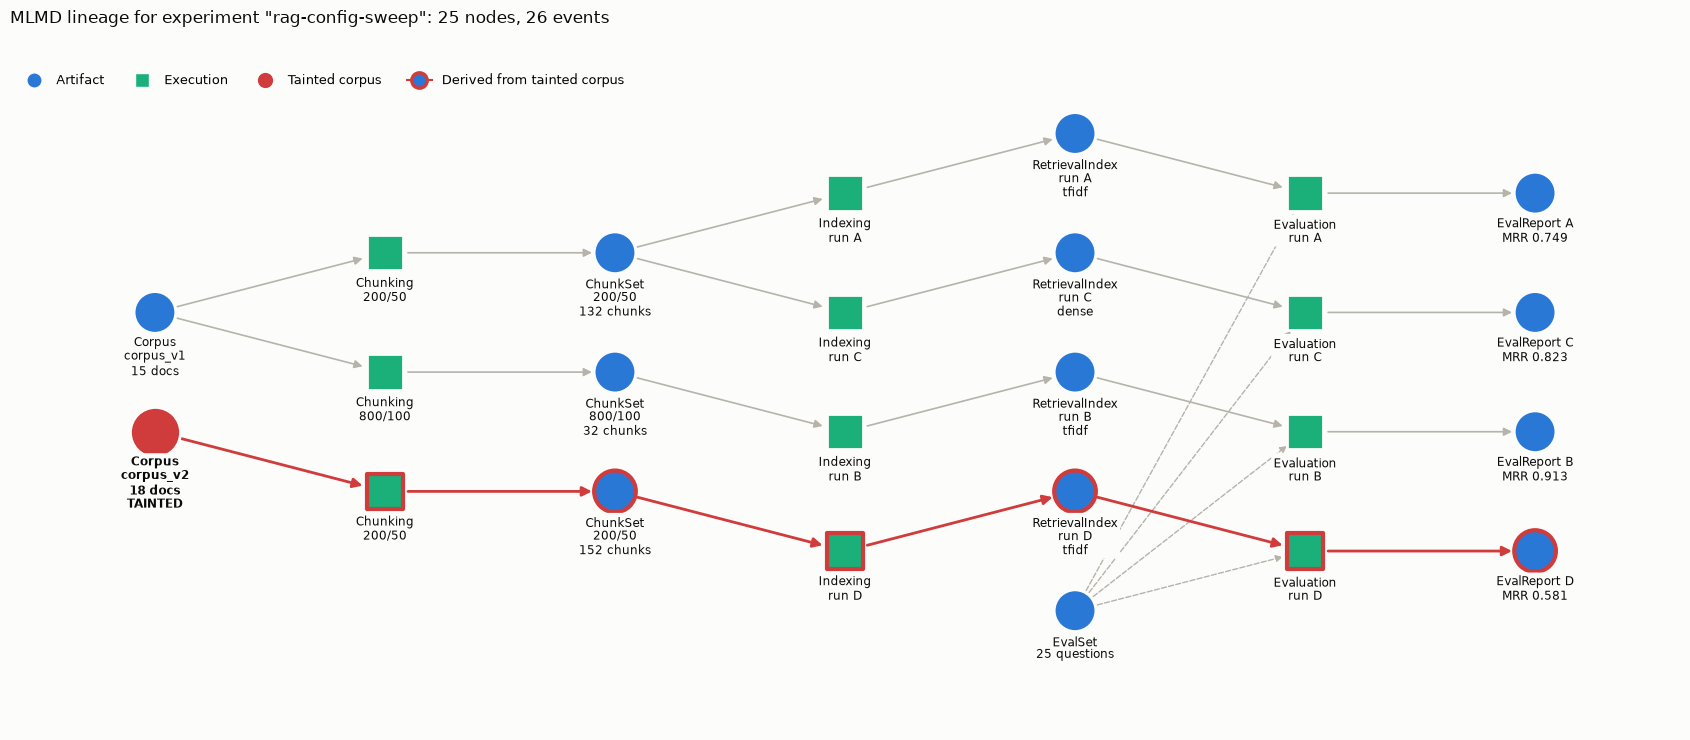

In [24]:
ARTIFACT_COLOR, EXECUTION_COLOR, TAINT_COLOR = '#2a78d6', '#1baf7a', '#d03b3b'
SURFACE, INK, MUTED_INK, EDGE_COLOR = '#fcfcfb', '#0b0b0b', '#52514e', '#b5b3aa'


def node_label(kind, node):
    p = props(node)
    if kind == 'artifact':
        t = artifact_type_names[node.type_id]
        if t == 'Corpus':
            return f"Corpus\n{node.name}\n{p['num_docs']} docs"
        if t == 'ChunkSet':
            return f"ChunkSet\n{p['chunk_size']}/{p['overlap']}\n{p['num_chunks']} chunks"
        if t == 'RetrievalIndex':
            return f"RetrievalIndex\nrun {node.name.split('__')[-1]}\n{p['retriever']}"
        if t == 'EvalSet':
            return f"EvalSet\n{p['num_questions']} questions"
        return f"EvalReport {p['run_name']}\nMRR {p['mrr']:.3f}"
    t = execution_type_names[node.type_id]
    if t == 'Chunking':
        return f"Chunking\n{p['chunk_size']}/{p['overlap']}"
    return f"{t}\nrun {p['run_name']}"


def build_lineage_graph():
    graph = nx.DiGraph()
    for a in store.get_artifacts_by_context(expt.id):
        graph.add_node(f'a{a.id}', kind='artifact', label=node_label('artifact', a))
    executions = store.get_executions_by_context(expt.id)
    for e in executions:
        graph.add_node(f'e{e.id}', kind='execution', label=node_label('execution', e))
    for ev in store.get_events_by_execution_ids([e.id for e in executions]):
        if ev.type == INPUT:
            graph.add_edge(f'a{ev.artifact_id}', f'e{ev.execution_id}')
        elif ev.type == OUTPUT:
            graph.add_edge(f'e{ev.execution_id}', f'a{ev.artifact_id}')
    return graph


def layered_layout(graph):
    """Columns by longest path from the inputs; rows ordered by the average row of each node's parents."""
    layer = {}
    for n in nx.topological_sort(graph):
        parents = list(graph.predecessors(n))
        layer[n] = max(layer[p] for p in parents) + 1 if parents else 0
    for n in graph.nodes:  # pull raw inputs (e.g. the EvalSet) next to their first consumer
        if graph.in_degree(n) == 0:
            layer[n] = min(layer[c] for c in graph.successors(n)) - 1
    pos = {}
    for col in sorted(set(layer.values())):
        nodes = [n for n in graph.nodes if layer[n] == col]
        def sort_key(n):
            parents = [pos[p][1] for p in graph.predecessors(n) if p in pos]
            return (-np.mean(parents) if parents else float('inf'), graph.nodes[n]['label'])
        nodes.sort(key=sort_key)
        for row, n in enumerate(nodes):
            pos[n] = (col * 2.2, (len(nodes) - 1) / 2 - row)
    return pos


graph = build_lineage_graph()
pos = layered_layout(graph)
taint_node = f'a{suspect_corpus_id}'
blast = nx.descendants(graph, taint_node)

fig, ax = plt.subplots(figsize=(17, 7.5), facecolor=SURFACE)
ax.set_facecolor(SURFACE)

edges = list(graph.edges)
red_edges = [e for e in edges if e[0] in blast | {taint_node} and e[1] in blast]
shared_edges = [e for e in edges if graph.out_degree(e[0]) > 2 and e not in red_edges]  # the EvalSet fan-out
plain_edges = [e for e in edges if e not in red_edges and e not in shared_edges]
nx.draw_networkx_edges(graph, pos, edgelist=plain_edges, ax=ax,
                       edge_color=EDGE_COLOR, width=1.2, arrowsize=12, node_size=1100)
nx.draw_networkx_edges(graph, pos, edgelist=shared_edges, ax=ax, style='dashed',
                       edge_color=EDGE_COLOR, width=1.0, arrowsize=10, node_size=1100)
nx.draw_networkx_edges(graph, pos, edgelist=red_edges, ax=ax,
                       edge_color=TAINT_COLOR, width=2.0, arrowsize=14, node_size=1100)

artifacts = [n for n, d in graph.nodes(data=True) if d['kind'] == 'artifact' and n != taint_node]
executions = [n for n, d in graph.nodes(data=True) if d['kind'] == 'execution']
for nodelist, shape, color, size in [(artifacts, 'o', ARTIFACT_COLOR, 900), (executions, 's', EXECUTION_COLOR, 650)]:
    nx.draw_networkx_nodes(graph, pos, nodelist=nodelist, node_shape=shape, node_color=color, node_size=size, ax=ax,
                           edgecolors=[TAINT_COLOR if n in blast else SURFACE for n in nodelist],
                           linewidths=[3.0 if n in blast else 2.0 for n in nodelist])
nx.draw_networkx_nodes(graph, pos, nodelist=[taint_node], node_shape='o', node_color=TAINT_COLOR,
                       node_size=1300, edgecolors=SURFACE, linewidths=2.0, ax=ax)

for n, (x, y) in pos.items():
    label = graph.nodes[n]['label'] + ('\nTAINTED' if n == taint_node else '')
    ax.text(x, y - 0.2, label, ha='center', va='top', fontsize=8.5, color=INK, linespacing=1.15,
            fontweight='bold' if n == taint_node else 'normal', zorder=5,
            bbox=dict(boxstyle='round,pad=0.2', facecolor=SURFACE, edgecolor='none'))

legend_handles = [
    Line2D([], [], marker='o', linestyle='', markersize=11, markerfacecolor=ARTIFACT_COLOR, markeredgecolor=SURFACE, label='Artifact'),
    Line2D([], [], marker='s', linestyle='', markersize=10, markerfacecolor=EXECUTION_COLOR, markeredgecolor=SURFACE, label='Execution'),
    Line2D([], [], marker='o', linestyle='', markersize=12, markerfacecolor=TAINT_COLOR, markeredgecolor=SURFACE, label='Tainted corpus'),
    Line2D([], [], marker='o', linestyle='-', color=TAINT_COLOR, markersize=11, markerfacecolor=ARTIFACT_COLOR,
           markeredgecolor=TAINT_COLOR, markeredgewidth=2.5, label='Derived from tainted corpus'),
]
ax.legend(handles=legend_handles, loc='upper left', bbox_to_anchor=(0, 1.0), frameon=False, fontsize=9, ncol=4)
ax.set_title(f'MLMD lineage for experiment "{expt.name}": {graph.number_of_nodes()} nodes, '
             f'{graph.number_of_edges()} events', loc='left', fontsize=12, color=INK, pad=28)
ax.axis('off')
ys = [y for _, y in pos.values()]
ax.set_ylim(min(ys) - 1.0, max(ys) + 0.6)
fig.tight_layout()

graph_path = os.path.join(ASSETS_DIR, 'lineage_graph.png')
fig.savefig(graph_path, dpi=160, facecolor=SURFACE, bbox_inches='tight')
print('Saved', graph_path)
plt.show()

### Wrap Up

In this notebook you used ML Metadata to answer "why did the chatbot answer wrong?" without reading any pipeline code:

* **Query 1** used the `Experiment` context to collect every `EvalReport` and rank them, which picked out the worst run.
* **Query 2** walked `OUTPUT` and `INPUT` events backward from that report to its raw inputs, then compared lineages across runs. The worst run differed from its closest neighbor only in the corpus.
* **Query 3** walked forward from that corpus to list every index and report built from it, which is the list of things to retire.
* **Query 4** followed the report's `uri` to the per-question results and showed the actual chunk that was retrieved instead of the right one, from a doc that only exists in the tainted corpus.

Because the store is a SQLite file, all of this still works tomorrow, or for a teammate with nothing but `metadata/rag_lineage.db`. In a TFX pipeline these records are written for you by every component, and the queries above work the same way against that store.